In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import snntorch as snn
from snntorch import surrogate
from snntorch import utils
import numpy as np
from matplotlib import pyplot as plt
import pandas as pd
import json

import dill
from tqdm import tqdm
import os
from typing import Callable, Any
from functools import partial
import random

from src.util.metric import MultiMetricBuilder
from src.util.tracer import Tracer
from src.util.dataloading import create_nmnist_dataloaders, create_shd_binary_dataloaders, create_shd_dataloaders, create_imu_dataloaders, create_fortiss_dataloaders
from src.util.classifier_per_timestep import ClassifierTrainer
from typing import Union

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "Arial", "Helvetica"],
    "font.size": 7,              # Default font size for axis/tick labels
    "axes.labelsize": 7,         # Font size for axis labels
    "axes.titlesize": 7,         # Font size for plot titles
    "xtick.labelsize": 7,        # Font size for tick labels (5-7 pt range)
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,       # Line weight for the axes frame
    "lines.linewidth": 1.0,      # Default line weight for data plots
    "pdf.fonttype": 42,          # Ensures text remains editable in Inkscape
    "ps.fonttype": 42,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False
})

mm = 1/25.4
width_sc = 89 * mm
height_sc = 70 * mm

save_plots = True
if save_plots:
    dir_path = "plots/figure_5/"
    os.makedirs(dir_path, exist_ok=True)

np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

/home/thomas/Development/online-local-gesture-activation/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import snntorch as snn
from snntorch import surrogate
from snntorch import utils
import numpy as np
from matplotlib import pyplot as plt
import json

import dill
from tqdm import tqdm
import os
from typing import Callable, Any
from functools import partial

from src.util.metric import MultiMetricBuilder
from src.util.tracer import Tracer
from src.util.dataloading import create_nmnist_dataloaders, create_shd_binary_dataloaders, create_shd_dataloaders, create_imu_dataloaders, create_fortiss_dataloaders
from src.util.classifier_per_timestep import ClassifierTrainer
from typing import Union

class Block(nn.Module):
    def __init__(
            self, 
            in_features:int, 
            out_features:int, 
            beta:float, 
            spike_grad:Callable,
            init_hidden:bool,
        ) -> None:
        super().__init__()
        
        self.ff = nn.Linear(in_features, out_features, bias=False)
        nn.init.kaiming_uniform_(self.ff.weight, mode='fan_in', nonlinearity='tanh')
        # self.ff.weight = torch.nn.Parameter(self.ff.weight*3)
        self.leaky = snn.Leaky(beta=beta, spike_grad=spike_grad, init_hidden=init_hidden, output=True, learn_beta=False)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, Union[torch.Tensor, None]]:
        """
        input:
            x: presynaptic spikes: (T, B, C, H, W)
        output:
            spk_rec: (T, B, C', H', W')
            mem_rec: (T, B, C', H', W') | None
        """
        T = x.shape[0] 
        B = x.shape[1]
        x = x.reshape(T, B, -1) 
        spk_rec = []
        mem_rec = []
        utils.reset(self)  # resets hidden states for all LIF neurons in net
        for t in range(T):  # x.size(0) = number of time steps
            spk_out, mem_out = self.leaky(self.ff(x[t]))
            spk_rec.append(spk_out)
            mem_rec.append(mem_out)
        
        spk_rec = torch.stack(spk_rec)
        mem_rec = torch.stack(mem_rec)
        return spk_rec, mem_rec
    
    def step(self, x:torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        """
        input:
            x: presynaptic spikes: (B, N) or (B, C, H, W)
        output:
            spk_rec: (B, N')
            mem_rec: (B, N')
        """
        B = x.shape[0]
        x = x.reshape(B, -1)
        x = self.ff(x)
        spk_out, mem_out = self.leaky(x)
        return spk_out, mem_out
    
    def get_in_dim(self) -> torch.Tensor:
        return self.ff.in_features
    
    def get_out_dim(self) -> torch.Tensor:
        return self.ff.out_features

    def get_weight(self) -> torch.Tensor:
        return self.ff.weight
    
    def set_weight(self, weight:torch.Tensor) -> None:
        if isinstance(weight, torch.Tensor):
            weight = nn.Parameter(weight)
        self.ff.weight = weight

block1 = Block(
    in_features=700, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block2 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)

block_rand = Block(
    in_features=700, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)

path = "results/tdcl_full_online/shd/ff/6_layer_net_450neurons_with_val_split/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/1/"
checkpoint: dict[str, dict[str, Any]] = dill.load(open(path + "final_checkpoint.pkl", "rb"))
block1.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_1"]["state_dict"].items() if "layer" in key})
block2.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_2"]["state_dict"].items() if "layer" in key})

<All keys matched successfully>

# 5 E

In [3]:
from src.util.tracer import Tracer

def compute_sim_score_with_tracer(x: torch.Tensor, block:Block) -> torch.Tensor:
    x1, _ = block(x)
    tracer = Tracer(carry_state=False)
    tracer.add(gain=-0.8714, beta=0.89)
    tracer.add(gain=1.1816, beta=0.85)

    trace = tracer(x1)
    sim = trace[:-1,...] * x1[1:,...]
    sim = sim.sum(dim=-1)
    sim = sim.cpu().detach()
    sim = sim / (0.5 * 450)
    return sim

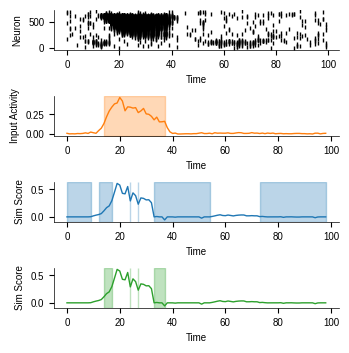

In [6]:
fig, ax = plt.subplots(4, 1, figsize=(width_sc, 90*mm))
i = 15

from src.util.dataloading import create_shd_dataloaders
train_loader, test_loader = create_shd_dataloaders(batch_size=128, bins=100, num_workers=4)
x, y = next(iter(test_loader))


from snntorch import spikeplot
spikeplot.raster(x[:,i,:], ax=ax[0], s=5, c="black", marker="|")

avg_act = x[1:, i, None, ...].mean(dim=2)
input_gate = ~(avg_act[:,0] < 0.1)
ax[1].fill_between(torch.arange(99), 0, 1, where=input_gate, 
                color='C1', alpha=0.3, 
                transform=ax[1].get_xaxis_transform(), 
                label='Input Gate')
ax[1].plot(avg_act, color="C1")

sim = compute_sim_score_with_tracer(x[:, i, None, ...], block1)
dynamic_gate = ~(sim[:,0] > avg_act[:,0])
ax[2].fill_between(torch.arange(99), 0, 1, where=dynamic_gate, 
                color='C0', alpha=0.3, 
                transform=ax[2].get_xaxis_transform(), 
                label='Dynamic Gate')
ax[2].plot(sim, color="C0")

combined_gate = ~((sim[:,0] > avg_act[:,0]) + (avg_act[:,0] < 0.1))
ax[3].fill_between(torch.arange(99), 0, 1, where=combined_gate, 
                color='C2', alpha=0.3, 
                transform=ax[3].get_xaxis_transform(), 
                label='Dynamic Gate')
ax[3].plot(sim, color="C2")

for axis in ax.flat:
    axis.set_xlabel("Time")
    
ax[0].set_ylabel("Neuron")
ax[1].set_ylabel("Input Activity")
ax[2].set_ylabel("Sim Score")
ax[3].set_ylabel("Sim Score")

fig.tight_layout()

if save_plots:
    data = {
        "input_activity": avg_act[:,0],
        "sim_score": sim[:,0],
        "input_gate": input_gate,
        "dynamic_gate": dynamic_gate,
        "combined_gate": combined_gate,
    }
    df = pd.DataFrame(data)
    df.to_csv(dir_path + "sample_evolution.csv")
    fig.savefig(dir_path + "sample_evolution.svg", bbox_inches="tight")

# 5 B

In [ ]:
block1 = Block(
    in_features=700, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block2 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block3 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block4 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block5 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)
block6 = Block(
    in_features=450, 
    out_features=450, 
    beta=0.5, 
    spike_grad=surrogate.atan(),
    init_hidden=True,
)


path = "results/tdcl_full_online/shd/ff/6_layer_net_450neurons_with_val_split/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100/1/"
checkpoint: dict[str, dict[str, Any]] = dill.load(open(path + "final_checkpoint.pkl", "rb"))
block1.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_1"]["state_dict"].items() if "layer" in key})
block2.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_2"]["state_dict"].items() if "layer" in key})
block3.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_3"]["state_dict"].items() if "layer" in key})
block4.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_4"]["state_dict"].items() if "layer" in key})
block5.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_5"]["state_dict"].items() if "layer" in key})
block6.load_state_dict({key[6:]: state_dict for key, state_dict in checkpoint[f"layer_6"]["state_dict"].items() if "layer" in key})

<All keys matched successfully>

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
block1 = block1.to(device)
block2 = block2.to(device)
block3 = block3.to(device)
block4 = block4.to(device)
block5 = block5.to(device)
block6 = block6.to(device)

xs0 = []
xs1 = []
xs2 = []
xs3 = []
xs4 = []
xs5 = []
xs6 = []
ys = []
for x, y in tqdm(test_loader):
    x = x.to(device)
    x1, _ = block1(x)
    x2, _ = block2(x1)
    x3, _ = block3(x2)
    x4, _ = block4(x3)
    x5, _ = block5(x4)
    x6, _ = block6(x5)
    xs0.extend([value.item() for value in x.mean(dim=(0, 2))])
    xs1.extend([value.item() for value in x1.mean(dim=(0, 2))])
    xs2.extend([value.item() for value in x2.mean(dim=(0, 2))])
    xs3.extend([value.item() for value in x3.mean(dim=(0, 2))])
    xs4.extend([value.item() for value in x4.mean(dim=(0, 2))])
    xs5.extend([value.item() for value in x5.mean(dim=(0, 2))])
    xs6.extend([value.item() for value in x6.mean(dim=(0, 2))])
    ys.extend([value.item() for value in y])
xs0 = np.array(xs0)
xs1 = np.array(xs1)
xs2 = np.array(xs2)
xs3 = np.array(xs3)
xs4 = np.array(xs4)
xs5 = np.array(xs5)
xs6 = np.array(xs6)
ys = np.array(ys)

100%|██████████| 18/18 [00:03<00:00,  4.83it/s]


In [17]:
device = "cuda" if torch.cuda.is_available() else "cpu"
block1 = block1.to(device)
block2 = block2.to(device)
block3 = block3.to(device)
block4 = block4.to(device)
block5 = block5.to(device)
block6 = block6.to(device)

xs0 = []
xs1 = []
xs2 = []
xs3 = []
xs4 = []
xs5 = []
xs6 = []
ys = []
for x, y in tqdm(test_loader):
    x = x.to(device)
    x1, _ = block1(x)
    x2, _ = block2(x1)
    x3, _ = block3(x2)
    x4, _ = block4(x3)
    x5, _ = block5(x4)
    x6, _ = block6(x5)
    xs0.append(x.mean(dim=0))
    xs1.append(x1.mean(dim=0))
    xs2.append(x2.mean(dim=0))
    xs3.append(x3.mean(dim=0))
    xs4.append(x4.mean(dim=0))
    xs5.append(x5.mean(dim=0))
    xs6.append(x6.mean(dim=0))
    ys.append(y)
xs0 = torch.concatenate(xs0, dim=0)
xs1 = torch.concatenate(xs1, dim=0)
xs2 = torch.concatenate(xs2, dim=0)
xs3 = torch.concatenate(xs3, dim=0)
xs4 = torch.concatenate(xs4, dim=0)
xs5 = torch.concatenate(xs5, dim=0)
xs6 = torch.concatenate(xs6, dim=0)
ys = torch.concatenate(ys, dim=0)

  0%|          | 0/18 [00:00<?, ?it/s]

100%|██████████| 18/18 [00:03<00:00,  4.66it/s]


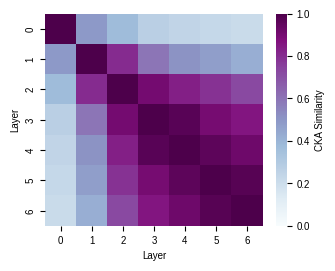

In [37]:
def linear_cka(X, Y):
    """X: (batch, neurons_x), Y: (batch, neurons_y)"""
    # Center
    X = X - X.mean(dim=0)
    Y = Y - Y.mean(dim=0)
    
    # Gram matrices (similarity between samples)
    KX = X @ X.T  # (batch, batch)
    KY = Y @ Y.T  # (batch, batch)
    
    hsic_xy = (KX * KY).sum()
    hsic_xx = (KX * KX).sum()
    hsic_yy = (KY * KY).sum()
    
    return (hsic_xy / (torch.sqrt(hsic_xx * hsic_yy) + 1e-8)).item()

# Build the similarity matrix
xs_rates = [xs0, xs1, xs2, xs3, xs4, xs5, xs6]
sims = np.zeros((len(xs_rates), len(xs_rates)))
for i, r1 in enumerate(xs_rates):
    for j, r2 in enumerate(xs_rates):
        sims[i, j] = linear_cka(r1, r2)

import seaborn as sns
import matplotlib.ticker as mtick
import pandas as pd
colors = sns.color_palette("colorblind", 7)

figsize = (width_sc, height_sc)
fig, ax = plt.subplots(1, 1, figsize=figsize)
df_cm = pd.DataFrame(sims, range(sims.shape[0]), range(sims.shape[1]))

sns.heatmap(df_cm, annot=False, cmap="BuPu", vmin=0.0, vmax=1.0) # font size

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=7)

ax.set_xticklabels(range(0, 7))
ax.set_yticklabels(range(0, 7))

ax.set_xlabel("Layer")
ax.set_ylabel("Layer")
cbar.ax.set_ylabel("CKA Similarity")

if save_plots:
    data = {f"Layer_{i}": sims[i,...] for i in range(sims.shape[0])}
    df_save = pd.DataFrame(data, data.keys())
    df_save.index.name = "Layer"
    df_save.to_csv(dir_path + "activity_similarity.csv")
    fig.savefig(dir_path + "activity_similarity.svg", bbox_inches="tight")

# 5 A

In [25]:
def create_subplot_single_column() -> tuple[plt.Figure, plt.Axes]:
    fig, ax = plt.subplots(figsize=(width_sc, height_sc))
    ax.spines[["top", "right"]].set_visible(False)
    return fig, ax

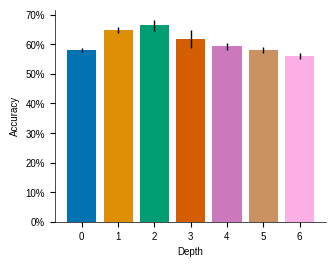

In [ ]:
from glob import glob
import numpy as np
from matplotlib import pyplot as plt
import matplotlib.ticker as mtick
import dill
import seaborn as sns


colors = sns.color_palette("colorblind", 7)

path = "results/tdcl_full_online/shd/ff/6_layer_net_450neurons_with_val_split/B1_bins100rotate5_beta0.5_(-0.8714_0.90)_(1.1816_0.85)_carry_warmp_up20_inp_thr0.01_lr(8e-2_4e-3)_tmp(0.5_0.25)_gamma1.0_epochs100"
files = glob(path + "/*/final_checkpoint.pkl")

def get_accuracies(chkp: dict, val_split:bool, all_out:bool) -> list[float]:
    base_key = "classifying"
    if not all_out:
        identifiers = list(map(lambda x: str(x), range(7)))
    else:
        identifiers = []
        for i in range(7):
            identifier = ""
            for j in range(i+1):
                identifier += str(j)
            identifiers.append(identifier)
    
    accs = []
    for identifier in identifiers:
        if val_split:
            val_accs = chkp[base_key+identifier]["val_acc"]
            val_accs = np.array(val_accs.cpu())
            best_idx = np.argmax(val_accs)
            test_accs = chkp[base_key+identifier]["test_acc"]
            test_accs = np.array(test_accs.cpu())
            best_test_acc = test_accs[best_idx]
        else:
            test_accs = chkp[base_key+identifier]["test_acc"]
            test_accs = np.array(test_accs.cpu())
            best_test_acc = np.max(test_accs)
        accs.append(best_test_acc)
    return accs

def get_accs_for_all_runs(files: list[str], val_split:bool, all_out:bool) -> np.ndarray:
    accs = []
    for file in files:
        chkp = dill.load(open(file, "rb"))
        accs.append(get_accuracies(chkp, val_split=val_split, all_out=all_out))
    accs = np.array(accs)
    return accs 

accs = get_accs_for_all_runs(files, val_split=False, all_out=False)
mean_accs = np.mean(accs, axis=0)
std_accs = np.std(accs, axis=0)

fig, ax = create_subplot_single_column()
ax.bar(np.arange(7), mean_accs, yerr=std_accs, color=colors)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_ylabel("Accuracy")
ax.set_xlabel("Depth")

if save_plots:
    data = {f"Run_{i}": accs[i,...] for i in range(accs.shape[0])}
    data.update({
        "Mean": accs.mean(axis=0),
        "Std": accs.std(axis=0)
    })
    df = pd.DataFrame(data, [f"Layer_{i}" for i in range(accs.shape[1])])
    df.index.name = "Accuracy"
    df.to_csv(dir_path + "accuracies_per_layer.csv")
    fig.savefig(dir_path + "accuracies_per_layer.svg", bbox_inches="tight") 

In [39]:
accs.shape

(4, 7)

# 5 D

(4, 6, 100)


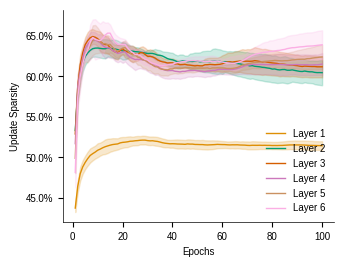

In [54]:
chkp = dill.load(open(files[0], "rb"))

def collect_metrics(files:list[str], metric_str:str) -> np.ndarray:
    """
    returns an array with all metrics in shape (runs, layers, metrics_str)
    """
    all_metrics = []
    for file in files:
        chkp = dill.load(open(file, "rb"))
        metrics = []
        for i in range(1, 7):
            metric = chkp["layer_"+str(i)]["test_metrics"][metric_str]._values
            metrics.append(metric)
        metrics = np.array(metrics)
        all_metrics.append(metrics)
    all_metrics = np.array(all_metrics)
    return all_metrics


us = collect_metrics(files, metric_str="update_sparcity")
print(us.shape)
mean_us = np.mean(us, axis=0)
std_us = np.std(us, axis=0)

fig, ax = create_subplot_single_column()
for i in range(mean_us.shape[0]):
    color = colors[i+1]
    ax.plot(range(1, 101), mean_us[i], color=color, label="Layer " + str(i+1))
    ax.fill_between(np.arange(1, 101), mean_us[i] - std_us[i], mean_us[i] + std_us[i], alpha=0.2, color=color)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Epochs")
ax.set_ylabel("Update Sparsity")
ax.legend()

if save_plots:
    for layer in range(us.shape[1]):
        data = {f"Run_{i}": us[i,layer,:] for i in range(us.shape[0])}
        data.update({
            "Mean": us[:,layer,:].mean(axis=0),
            "Std": us[:,layer,:].std(axis=0),
        })
        df = pd.DataFrame(data, [f"Epoch_{i+1}" for i in range(us.shape[2])])
        df.index.name = "Update Sparsity"
        df.to_csv(dir_path + f"update_sparsities_layer_{layer}.csv")

    fig.savefig(dir_path + "update_sparsities.svg", bbox_inches="tight")

# 5 C

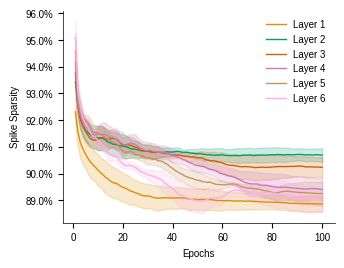

In [56]:
sm = collect_metrics(files, metric_str="spike_mean")
sm = 1 - sm
mean_sm = np.mean(sm, axis=0)
std_sm = np.std(sm, axis=0)

fig, ax = create_subplot_single_column()
for i in range(mean_sm.shape[0]):
    color = colors[i+1]
    ax.plot(range(1, 101), mean_sm[i], color=color, label="Layer " + str(i+1))
    ax.fill_between(range(1, 101), mean_sm[i] - std_sm[i], mean_sm[i] + std_sm[i], alpha=0.2, color=color)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Epochs")
ax.set_ylabel("Spike Sparsity")
ax.legend()

if save_plots:
    for layer in range(sm.shape[1]):
        data = {f"Run_{i}": sm[i,layer,:] for i in range(sm.shape[0])}
        data.update({
            "Mean": sm[:,layer,:].mean(axis=0),
            "Std": sm[:,layer,:].std(axis=0),
        })
        df = pd.DataFrame(data, [f"Epoch_{i+1}" for i in range(sm.shape[2])])
        df.index.name = "Spike Sparsity"
        df.to_csv(dir_path + f"spike_sparsities_layer_{layer}.csv")
    
    fig.savefig(dir_path + "spike_sparsities.svg", bbox_inches="tight")